# Marches aléatoires « ligne de base » : systèmes π et Hückel

Marches aléatoires dans l'espace chimique d'evomol, sans contrainte : toutes les mutations sont
permises et tous les filtres sont désactivés (ils restent réglables ci-dessous). À chaque pas, sur la
molécule visitée :
- `n_atoms` : nombre d'atomes lourds ;
- `PI_CHAIN_SIZE` : taille du plus grand système π connexe, `PCT_PI_ATOMS` : % des atomes lourds
  qui sont π, comptés comme dans `gap_pi_relation.ipynb` (atome π = aromatique ou sp2 / sp) ;
- Hückel : `HOMO`, `LUMO` et `gap` (λ).

Plusieurs marches tournent en parallèle (graines différentes). Le code est dans `scripts/Lea/pi_walk.py`.

In [3]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "evomol").is_dir())
sys.path.insert(0, str(ROOT / "scripts" / "Lea"))

import matplotlib.pyplot as plt
from IPython.display import display

import pi_walk as pw                         # scripts/Lea/pi_walk.py (se place à la racine du projet)

## Configuration

In [4]:
LABEL = "test"         # nom de l'expérience : dossier results/pi_walk/<LABEL>/
CONFIG = pw.make_config(
    # ── départ et marche
    START="c1ccccc1",              # SMILES d'où part le burn-in
    SEED=1,                        # marche k : burn-in SEED + 2k, marche SEED + 2k + 1 (même SEED :
    #   mêmes marches) ; autre entier : autres marches reproductibles ; None : au hasard à chaque lancement
    BURN_IN_STEPS=0,               # pas pour obtenir un départ aléatoire (0 : la marche part de START)
    N_STEPS=1000,                   # pas de la marche observée
    MAX_ATOMS=10000,               # nb max d'atomes lourds (défaut d'evomol)
    ACCEPTED_ATOMS=["C", "O", "N","S","F"],  
    UNIQUE_KEKULE=False,           # True : un seul SMILES par molécule aromatique (plus lent)
    ONLY_VALID=False,              # True : n'avancer que vers des voisins valides (sans filtre : tous)
    COUNT_VALID_NEIGHBORS=False,   # True : valider tout le voisinage à chaque pas
    EXCLUDE_CURRENT=True,          # True : la molécule courante n'est jamais son propre voisin
    ACTION_TYPES= ["AddAtomMG", "RemoveAtomMG","ChangeBondMG"],  # types de mutation autorisés
    #   None : toutes ; sinon parmi AddAtomMG, RemoveAtomMG, ChangeBondMG, CutAtomMG, MoveGroupMG,
    #   SubstituteAtomMG, InsertCarbonMG (si INSERT_CARBON), AddGroupMG (si WITH_ADD_GROUP),
    #   RemoveGroupMG (si WITH_REMOVE_GROUP)
    UNIFORM_ACTION_TYPE=True,      # True : tirer d'abord le type de mutation au hasard (uniforme parmi les
    #   types autorisés qui ont un voisin), puis un voisin de ce type : aucun type n'est surreprésenté.
    #   False : voisin tiré uniformément (les types qui produisent beaucoup de voisins dominent)
    # ── espace d'action (ligne de base : tout ce que sait faire evomol)
    INSERT_CARBON=True,             # InsertCarbonMG disponible
    AVOID_SP3_ON_SP3=False,         # True : AddAtomMG ne greffe pas de C sp3 sur un C sp3
    ADD_ATOM_MULTIPLE_BONDS=True,  # AddAtomMG peut greffer par double / triple liaison (=CH2, =O, #N…)
    AVOID_BOND_BREAKING=False,      # True : ChangeBondMG ne supprime jamais de liaison
    AVOID_BOND_FORMING=False,       # True : ChangeBondMG ne crée jamais de liaison
    BOND_CHANGE_BY_ONE=True,      # True : ChangeBondMG d'un cran à la fois (0→1, 1→2…) ; False : comme
    #   l'EvoMol d'origine, n'importe quel ordre en une mutation (0→2, 1→3, 3→0…)
    WITH_ADD_GROUP=False,           # AddGroupMG (thiophène, benzène, nitro, azide, sulfonique)
    WITH_REMOVE_GROUP=False,        # RemoveGroupMG
    # ── filtres (ordre : Hückel → sp3 → ChEMBL/ZINC → Hetero) : tous désactivés
    FILTER_HUCKEL=False,           # True : tout C sp3 doit être en bout de chaîne
    MAX_SP3=None,                  # None : inactif ; entier : nb max d'atomes sans liaison π
    FILTER_REALISM=None,           # "chembl_zinc", "chembl" ou None
    FILTER_HETERO=False,           # True : chaînes d'hétéroatomes
    MAX_RING_N=None,                  # nb max d'azotes en cycle (si FILTER_HETERO)
)
N_WALKS = 1                        # marches (graines 0 … N_WALKS − 1)
N_JOBS = None                      # processus en parallèle (None : nb de cœurs − 1)
OUT_DIR = f"notebooks/random_walk/results/pi_walk/{LABEL}"  # relatif à la racine du projet
FIGURES = Path(OUT_DIR) / "figures"

## Lancement

Les marches tournent en parallèle ; la barre suit tous les pas (burn-in compris). Relancer avec le même
`LABEL` écrase les marches et les figures de ce dossier : changer `LABEL` pour garder une expérience.

In [5]:
pw.run_walks(CONFIG, N_WALKS, OUT_DIR, N_JOBS)
walks = pw.load_walks(OUT_DIR)
for k, meta in pw.load_meta(OUT_DIR).items():
    print(f"marche {k} : départ {meta['walk_start']}  ({meta['t_total']:.0f} s)")
print("filtres :", meta["filters"] or "aucun")
print("mutations :", ", ".join(meta["actions"]))

notebooks/random_walk/results/pi_walk/test : marches précédentes écrasées


pas:   0%|          | 0/1000 [00:00<?, ?it/s]

terminé en 1.3 min
marche 0 : départ C1=CC=CC=C1  (75 s)
filtres : aucun
mutations : AddAtomMG, RemoveAtomMG, ChangeBondMG


## Mutations réalisées

Nombre de fois où chaque mutation a été faite, par marche puis au total (burn-in exclu). Les mutations
disponibles jamais faites apparaissent à 0 ; « restart » : retour au départ faute de voisin.

In [6]:
walks = pw.load_walks(OUT_DIR)
actions = next(iter(pw.load_meta(OUT_DIR).values()))["actions"]   # mutations disponibles (même liste pour toutes les marches)
display(pw.mutation_counts(walks, actions))

,marche 0,total,%
action,,,
AddAtomMG,362,362,36.2
ChangeBondMG,334,334,33.4
RemoveAtomMG,304,304,30.4


## Détail des mutations : atome ajouté, atome retiré, saut de liaison

Retrouvé sans relancer les marches, à partir des SMILES de deux pas successifs : pour chaque
AddAtomMG, l'élément greffé et l'ordre de la liaison (`+=O` : O greffé par une double liaison) ; pour
chaque RemoveAtomMG, l'élément retiré ; pour chaque ChangeBondMG, l'ordre de la liaison avant → après
(`0→1` : liaison créée, `1→0` : liaison rompue). Écrit dans `mutations_detail.csv` du dossier de
l'expérience. Une barre par mutation, segments triés du plus fréquent au moins fréquent
(`figures/05_mutations_detail.png`) ; puis la même figure pour toutes les expériences de `results/pi_walk/`.

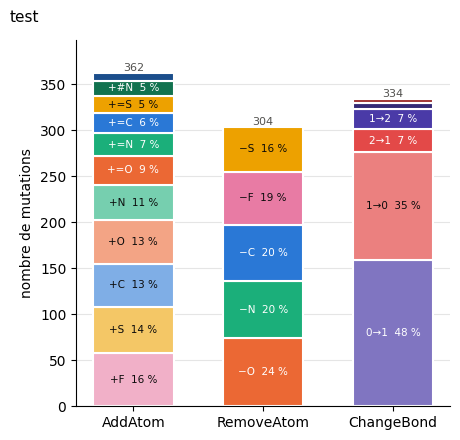

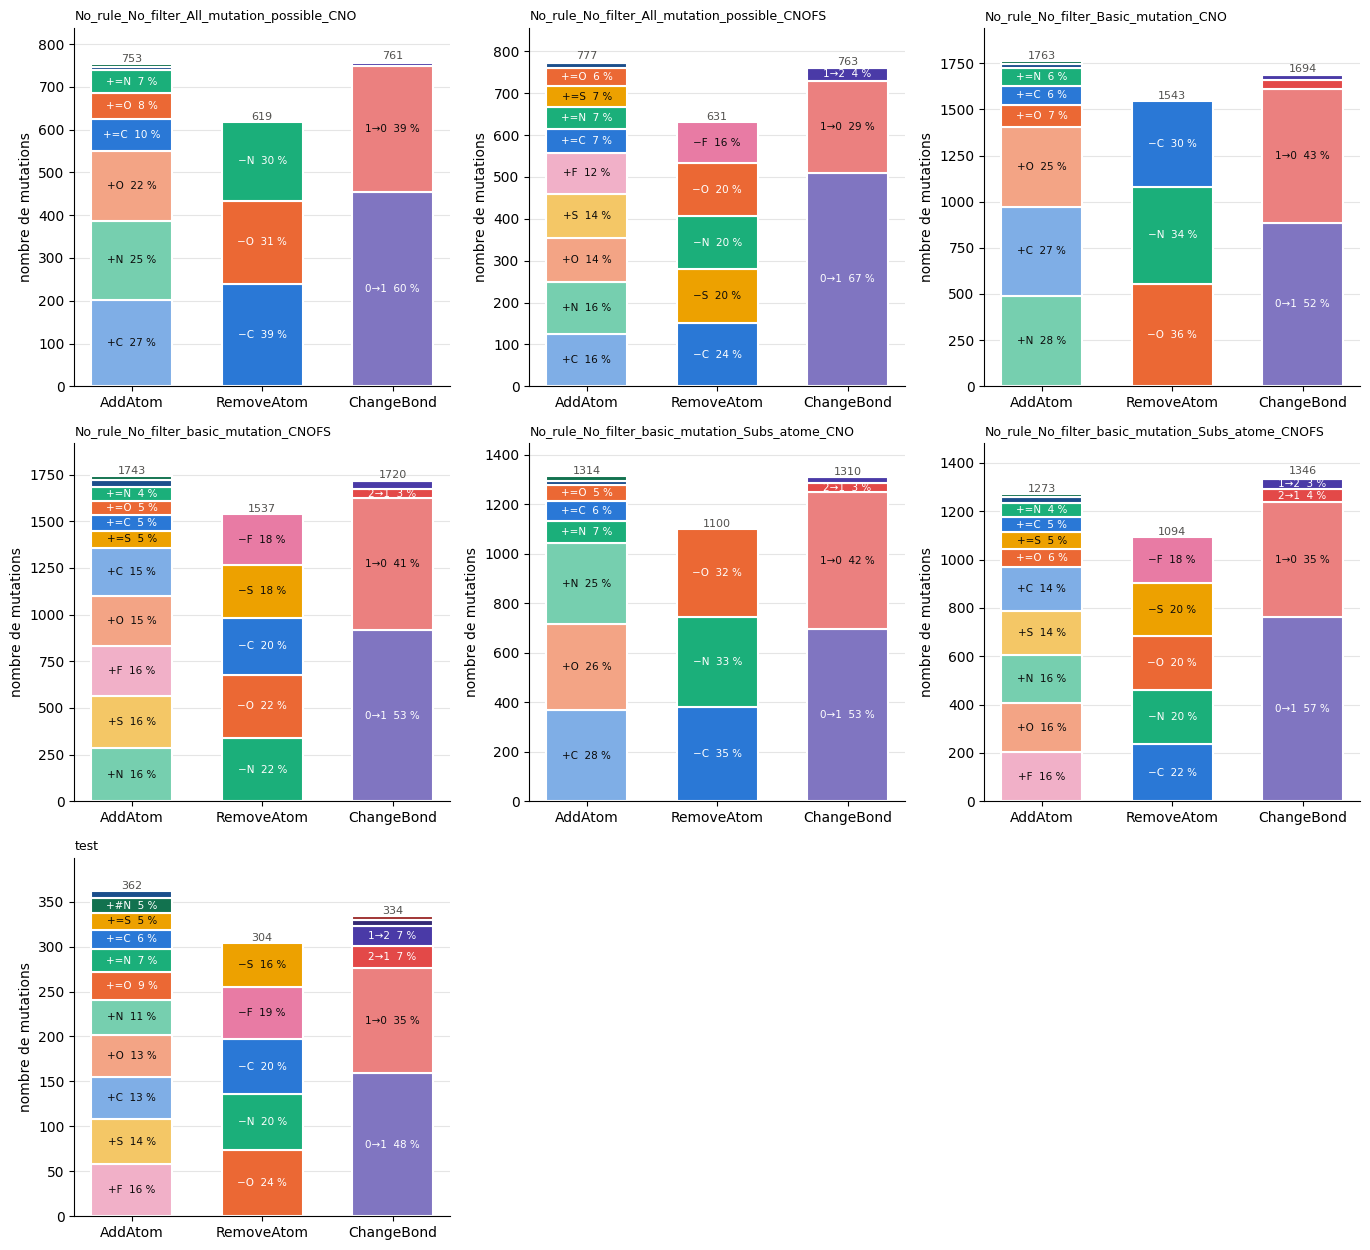

In [7]:
details = pw.mutation_details(OUT_DIR, N_JOBS)       # ~30 s à 1,5 min par expérience de 10 marches
pw.plot_mutation_details({LABEL: details}, save=FIGURES / "05_mutations_detail.png")
plt.show()

# toutes les expériences (mutations_detail.csv déjà écrit, sinon calculé)
RESULTS = Path("notebooks/random_walk/results/pi_walk")
all_details = {}
for path in sorted(p for p in RESULTS.iterdir() if p.is_dir() and list(p.glob("walk*_meta.json"))):
    csv = path / "mutations_detail.csv"
    all_details[path.name] = pw.pd.read_csv(csv) if csv.exists() else pw.mutation_details(path, N_JOBS)
pw.plot_mutation_details(all_details, save=RESULTS / "mutations_detail.png")
plt.show()

## Décompte des atomes et des mutations

Pour chaque marche : total des C, O, N, S, F et H sur toutes les molécules visitées (pas 0 compris,
burn-in exclu), et part de chaque mutation en % des pas de la marche ; puis la moyenne entre marches.
Écrit dans `decompte.csv` du dossier de l'expérience (à chaque lancement ; cette cellule le refait
aussi pour une expérience déjà faite).
Histogramme : moyennes entre marches en %, part de chaque élément parmi tous les atomes (H compris)
et part de chaque mutation parmi les pas (`figures/04_decompte.png`) ; le CSV garde les nombres d'atomes.

,decompte,nom,marche 0,moyenne
0,atome,C,9778,9778.0
1,atome,O,3264,3264.0
2,atome,N,6616,6616.0
3,atome,S,10738,10738.0
4,atome,F,852,852.0
5,atome,H,12114,12114.0
6,mutation (%),AddAtomMG,36.2,36.2
7,mutation (%),ChangeBondMG,33.4,33.4
8,mutation (%),RemoveAtomMG,30.4,30.4


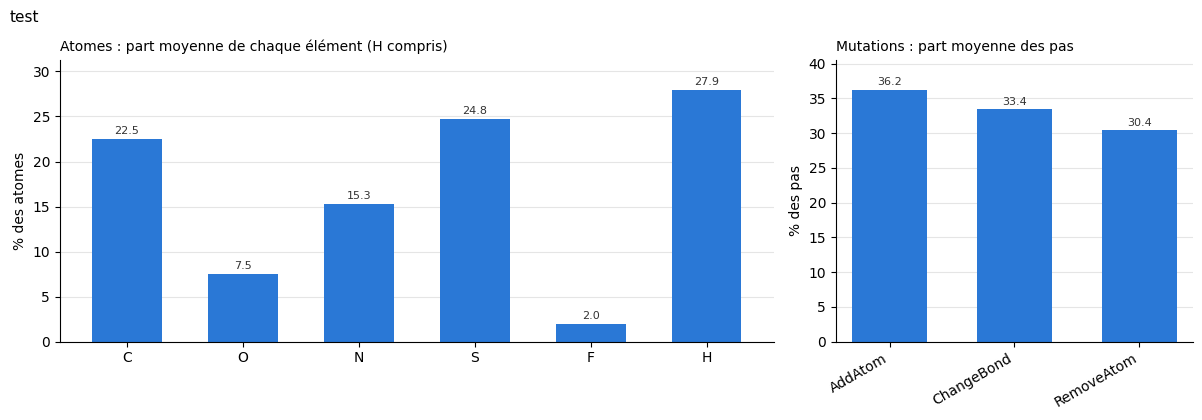

In [8]:
counts = pw.write_counts(OUT_DIR)
display(counts)
pw.plot_counts(counts, save=FIGURES / "04_decompte.png")
plt.show()

## Marches individuelles

Un graphe par variable, une courbe par marche. Un calcul qui échoue (Hückel impossible) est tracé à −2.

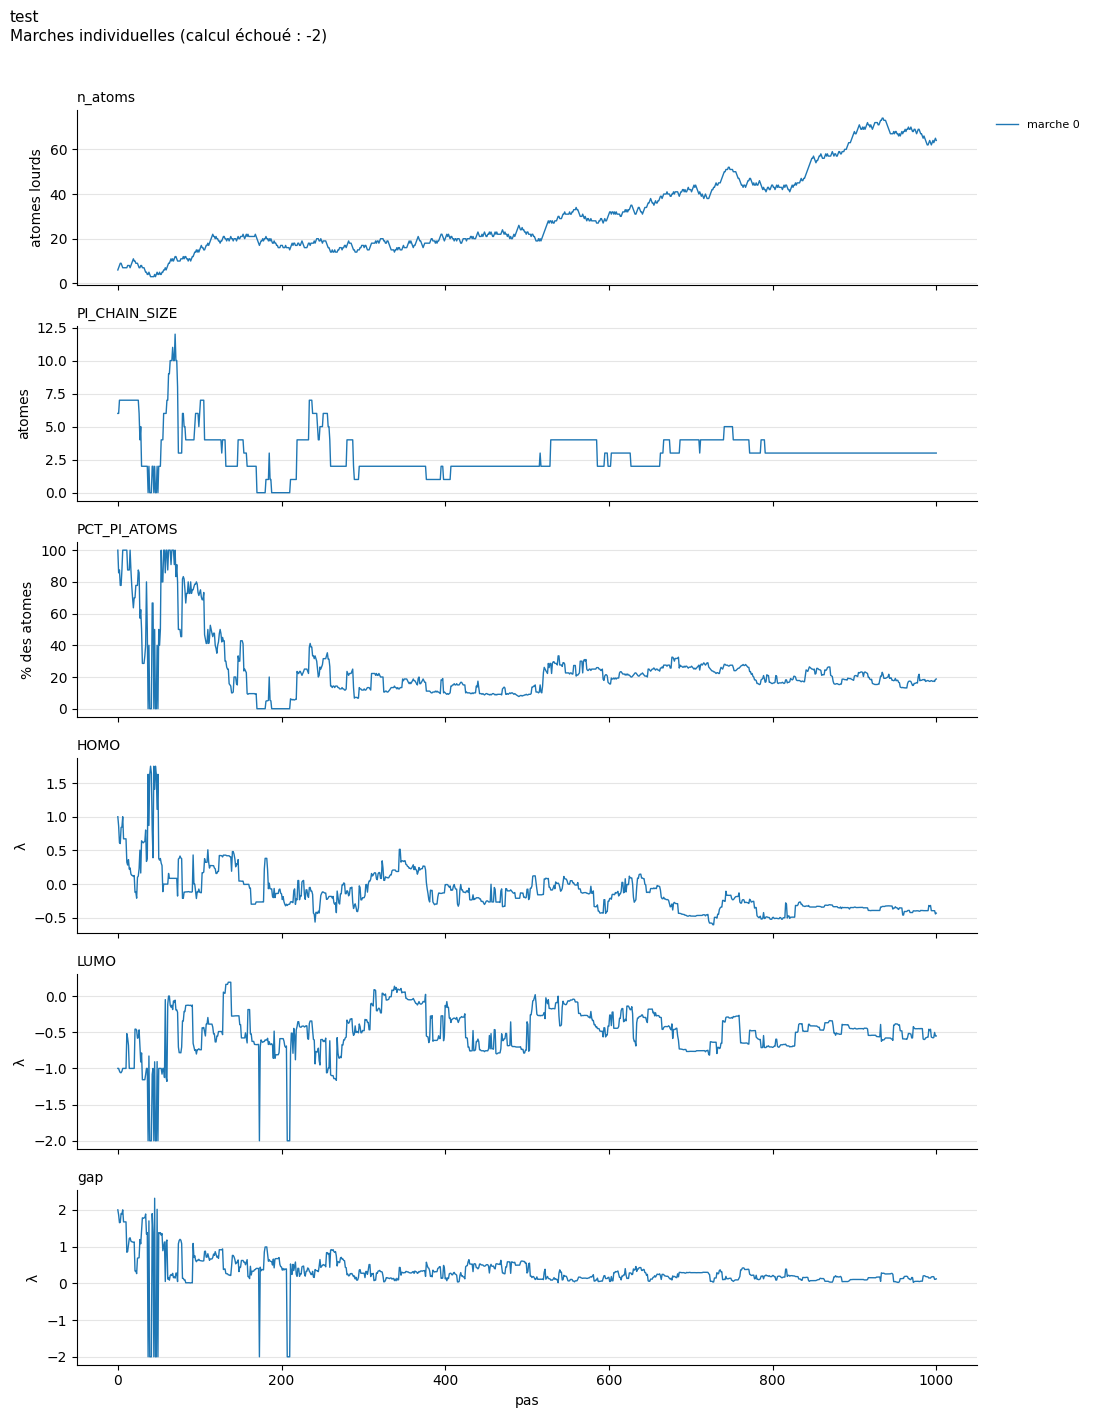

In [9]:
pw.plot_walks(walks, save=FIGURES / "01_marches.png")
plt.show()

## Longueur d'autocorrélation

**ρ(k)** mesure à quel point la valeur d'une variable (ex. `gap`) à un pas ressemble encore à sa valeur
k pas plus loin. Pour une marche de valeurs $x_0, x_1, \dots, x_N$, on forme les paires
$(x_t, x_{t+k})$ pour tous les pas t, et ρ(k) est le coefficient de corrélation de Pearson entre les
deux colonnes :

$$\rho(k) = \frac{\sum_t (x_t - \bar{x})(x_{t+k} - \bar{x}')}{\sqrt{\sum_t (x_t - \bar{x})^2 \; \sum_t (x_{t+k} - \bar{x}')^2}}$$

($\bar{x}$ : moyenne des $x_t$, $\bar{x}'$ : moyenne des $x_{t+k}$ ; les pas où le calcul a échoué sont
exclus.)
- ρ(k) ≈ 1 : k pas plus loin, la valeur a peu changé (paysage lisse : une mutation change peu la
  propriété) ;
- ρ(k) ≈ 0 : plus aucun lien entre les deux valeurs (paysage rugueux à cette échelle) ;
- ρ(k) < 0 : les valeurs ont tendance à s'inverser.

ρ(k) diminue en général quand k augmente. Si cette décroissance est exponentielle, ρ(k) ≈ ρ(1)ᵏ = e^(−k/ℓ),
d'où la **longueur de corrélation ℓ = −1/ln ρ(1)** : nombre de pas au bout duquel la corrélation est
tombée à 1/e ≈ 0,37. Plus ℓ est grand, plus la variable évolue lentement le long de la marche.

Tableau : ℓ par marche, puis moyenne et écart-type. Figure : ρ(k) moyen ± écart-type entre marches,
k = 1 … 100.

,ℓ marche 0,ℓ moyenne,ℓ écart-type
variable,,,
n_atoms,997.775,997.775,NaN
PI_CHAIN_SIZE,21.917,21.917,NaN
PCT_PI_ATOMS,16.848,16.848,NaN
HOMO,12.987,12.987,NaN
LUMO,9.400,9.400,NaN
gap,10.873,10.873,NaN


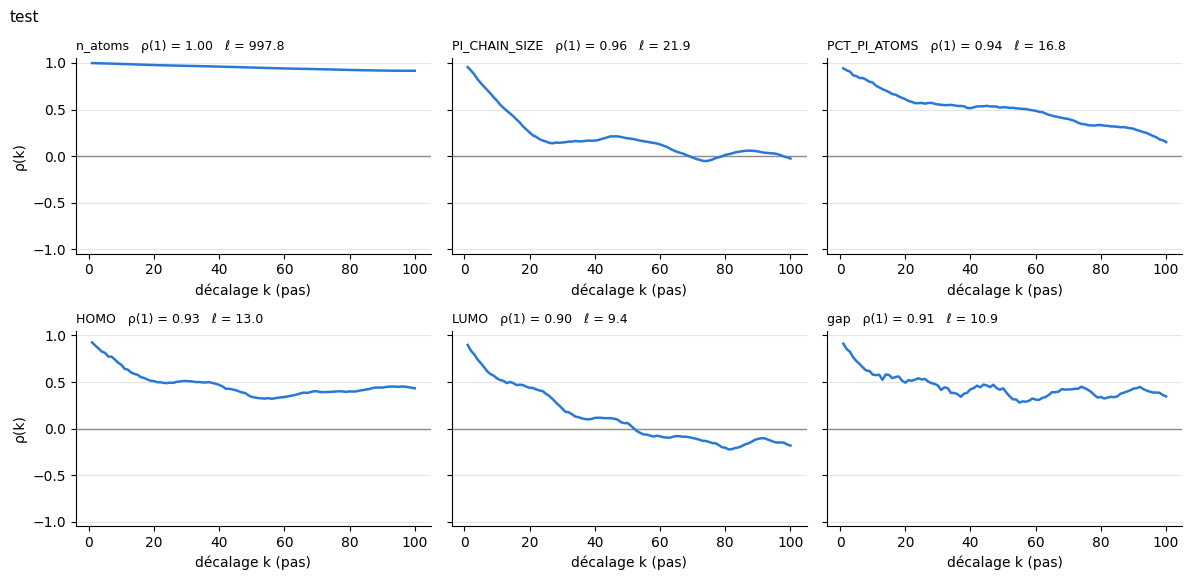

In [10]:
acf, rho = pw.autocorrelation(walks)
display(pw.autocorrelation_summary(acf).round(3))
pw.plot_autocorrelation(rho, pw.VARIABLES, save=FIGURES / "02_autocorrelation.png")
plt.show()


## Moyenne entre marches

Moyenne ± écart-type des marches à chaque pas (calculs échoués exclus).

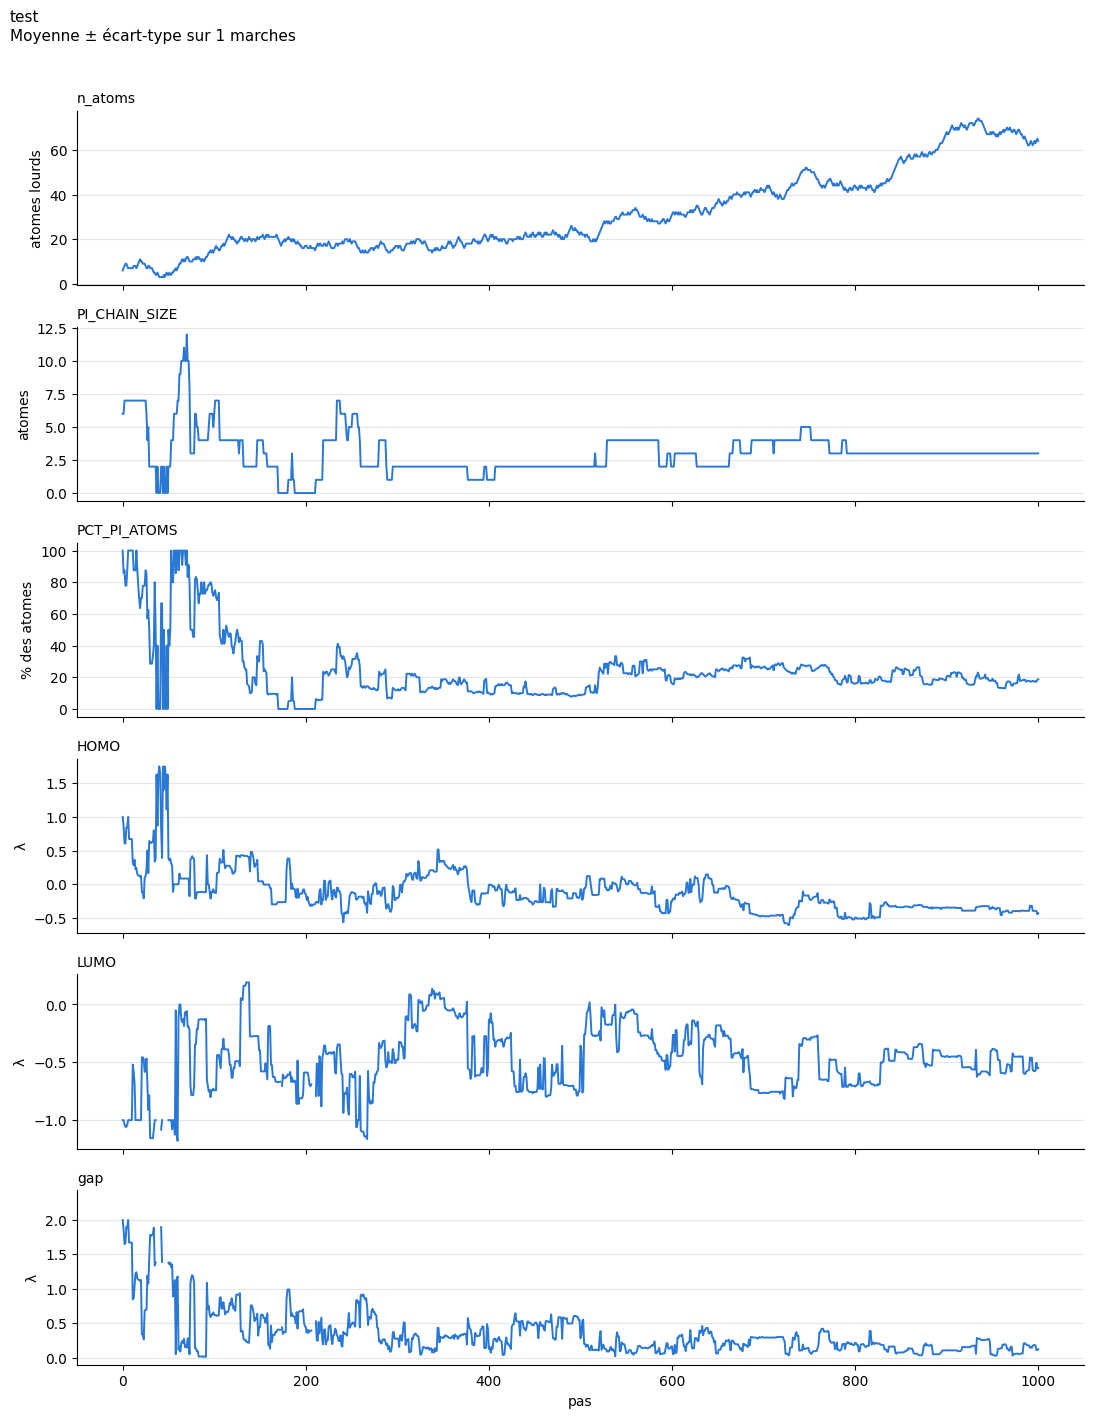

In [11]:
pw.plot_mean(walks, save=FIGURES / "03_moyenne.png")
plt.show()

## Variables deux à deux

Chaque variable contre chaque autre, sur tous les pas de toutes les marches : nuage de points et droite
de régression (bande : intervalle de confiance à 95 %), histogramme de chaque variable sur la
diagonale. Les calculs échoués sont exclus paire par paire (`figures/06_paires.png`).

In [ ]:
pw.plot_pairs(walks, save=FIGURES / "06_paires.png")
plt.show()

## Parcourir une marche

Choisir l'expérience (un `LABEL`), la marche et la plage de pas : molécules de chaque pas, 3 par ligne,
avec la mutation qui y mène et leurs valeurs.

/Applications/anaconda3/envs/revomol/lib/python3.12/site-packages/rdkit/Chem/Draw/IPythonConsole.py:261: UserWarning: Truncating the list of molecules to be displayed to 100. Change the maxMols value to display more.
  warnings.warn(




In [12]:
EXPERIENCE = LABEL                  # autre expérience : son LABEL
WALK = 0                            # numéro de la marche
STEP_START, STEP_STOP = 0,100       # pas affichés (inclus)

pw.show_steps(f"notebooks/random_walk/results/pi_walk/{EXPERIENCE}", WALK, STEP_START, STEP_STOP)